# LSTMD workload forecasting: standalone Kaggle notebook, all 4 table configurations

Standalone version of `lstmd_training.py` (`grass-overflow/ML_Proj`); it needs no repo clone, no `util/` or `models/` imports and no TensorFlow Probability.

It reproduces the four rows of the paper's Table 1 for **LSTMD** (Conv1D -> LSTM -> MLP -> Gaussian output, trained with negative log-likelihood):

| Label | Training | Prediction | Fits |
|---|---|---|---|
| **S-U-LSTMD** | single trace | univariate (CPU or memory) | 12 traces x 2 = 24 |
| **S-B-LSTMD** | single trace | bivariate (CPU + memory) | 12 |
| **M-U-LSTMD** | all 12 traces together | univariate | 2 (one per resource) |
| **M-B-LSTMD** | all 12 traces together | bivariate | 1 |

Each fit runs **500 epochs, 1 iteration** with the saved hyperparameters of that configuration (`hyperparams/{univariate,bivariate,multiunivariate,multibivariate}`). Table 1 = mean MSE/MAE over the 12 traces' test splits, CPU and memory. Window = 288, horizon = 2, 80/20 split per trace.

**Setup:** Add Input -> your **ML_PROJ_DATASET**, set Accelerator to GPU, Run All. Results and models are written to `/kaggle/working/lstmd_output/` after every fit. If the session stops, re-run and it resumes (finished fits are skipped).

In [1]:
# ---------- CONFIG ----------
import os, glob, json, time, zipfile
from pathlib import Path
from statistics import NormalDist
import numpy as np
import pandas as pd

MODES = ["S-U", "S-B", "M-U", "M-B"]   # any subset, e.g. ["M-B"] for a quick run
EPOCHS = 500
ITERATIONS = 1             # single training run per fit
WIN, HORIZON = 288, 2
TRAIN_SPLIT = 0.8
VAL_SPLIT = 0.2            # fraction of training windows held out for val_loss (as in the original script)
SEED = 0
RESUME = True              # skip fits already recorded in lstmd_output/LSTMD_fit_log.csv
LOG_EVERY = 25             # print a progress line every N epochs

# False = run all 500 epochs (best-val-loss weights are restored at the end).
# True  = stop early if val_loss doesn't improve for PATIENCE epochs.
EARLY_STOPPING = False
PATIENCE = 50

MODEL_NAME = "LSTMD"
TRACES = ["gc11", "gc19_a", "gc19_b", "gc19_c", "gc19_d", "gc19_e", "gc19_f", "gc19_g", "gc19_h",
          "ali18", "ali20_c", "ali20_g"]
RESOURCES = ["avgcpu", "avgmem"]      # channel 0 = CPU ("processing units"), channel 1 = memory
SERVICE_LEVELS = [0.90, 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99, 0.995]

# Paper Table 1, LSTMD rows: (CPU MSE, CPU MAE, Memory MSE, Memory MAE)
PAPER = {"S-U-LSTMD": (0.0040, 0.0455, 0.0041, 0.0420), "S-B-LSTMD": (0.0061, 0.0556, 0.0088, 0.0631),
         "M-U-LSTMD": (0.0041, 0.0464, 0.0044, 0.0439), "M-B-LSTMD": (0.0046, 0.0446, 0.0046, 0.0446)}

# Saved hyperparameters of every configuration (from the repo's hyperparams/ CSVs).
# Keys: "S-U|<trace>|<cpu|mem>", "S-B|<trace>", "M-U|<cpu|mem>", "M-B"
HP = json.loads('''{"S-U|gc11|cpu":{"first_conv_dim":64,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":16,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc11|mem":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc11":{"first_conv_dim":32,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_a|cpu":{"first_conv_dim":64,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_a|mem":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_a":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_b|cpu":{"first_conv_dim":128,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_b|mem":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_b":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"S-U|gc19_c|cpu":{"first_conv_dim":64,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_c|mem":{"first_conv_dim":128,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_c":{"first_conv_dim":64,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"S-U|gc19_d|cpu":{"first_conv_dim":32,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_d|mem":{"first_conv_dim":64,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_d":{"first_conv_dim":64,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_e|cpu":{"first_conv_dim":128,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_e|mem":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":1024,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_e":{"first_conv_dim":64,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_f|cpu":{"first_conv_dim":128,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"S-U|gc19_f|mem":{"first_conv_dim":32,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_f":{"first_conv_dim":128,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":16,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":1024,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_g|cpu":{"first_conv_dim":32,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.0001,"momentum":0.9,"decay":0.0001},"S-U|gc19_g|mem":{"first_conv_dim":32,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_g":{"first_conv_dim":64,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":16,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_h|cpu":{"first_conv_dim":32,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"S-U|gc19_h|mem":{"first_conv_dim":128,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.001},"S-B|gc19_h":{"first_conv_dim":128,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|ali18|cpu":{"first_conv_dim":64,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"rmsprop","lr":0.0001,"momentum":0.9,"decay":0.001},"S-U|ali18|mem":{"first_conv_dim":64,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|ali18":{"first_conv_dim":32,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|ali20_c|cpu":{"first_conv_dim":128,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|ali20_c|mem":{"first_conv_dim":128,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":16,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|ali20_c":{"first_conv_dim":32,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":16,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":1024,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.001},"S-U|ali20_g|cpu":{"first_conv_dim":64,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":1024,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|ali20_g|mem":{"first_conv_dim":64,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|ali20_g":{"first_conv_dim":64,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"M-U|cpu":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":8,"first_dense_dim":8,"first_dense_activation":"relu","mlp_units":[32,32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"M-U|mem":{"first_conv_dim":16,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":3,"second_lstm_dim":32,"first_dense_dim":8,"first_dense_activation":"relu","mlp_units":[32,16],"batch_size":1024,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"M-B":{"first_conv_dim":16,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":8,"first_dense_activation":"relu","mlp_units":[32,32],"batch_size":128,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001}}''')

OUT = Path("/kaggle/working/lstmd_output") if Path("/kaggle/working").exists() else Path("lstmd_output")
for sub in ("models", "history", "ckpt", "predictions"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus if gpus else "NONE (500-epoch fits on CPU will be extremely slow; set Accelerator to GPU)")

TensorFlow 2.20.0 | Keras 3.13.2
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Load the 12 traces from ML_PROJ_DATASET

Looks under `/kaggle/input` for the 12 CSVs (`time, avgcpu, avgmem`), so it works whatever the exact mount path is. The data is already normalized, so no extra scaler is applied.

In [2]:
DATASET_SLUG = "ml-proj-dataset"
def norm(x): return x.lower().replace("_", "-")

all_csvs = glob.glob("/kaggle/input/**/*.csv", recursive=True)
preferred = [p for p in all_csvs if DATASET_SLUG in norm(p)]
found = {}
for p in preferred + all_csvs:
    stem = Path(p).stem
    if stem in TRACES and stem not in found:
        found[stem] = p
missing = [t for t in TRACES if t not in found]
if missing:
    raise FileNotFoundError(f"Missing traces {missing}. Attach ML_PROJ_DATASET via Add Input. "
                            f"CSVs visible under /kaggle/input: {sorted(all_csvs)[:30]}")

series = {}
for t in TRACES:
    df = pd.read_csv(found[t])
    assert {"avgcpu", "avgmem"} <= set(df.columns), f"{t}: expected avgcpu/avgmem, got {list(df.columns)}"
    series[t] = df[RESOURCES].to_numpy(dtype=np.float32)
    print(f"{t:8s} {len(df):6d} rows  <- {found[t]}")

gc11       8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc11.csv
gc19_a     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_a.csv
gc19_b     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_b.csv
gc19_c     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_c.csv
gc19_d     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_d.csv
gc19_e     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_e.csv
gc19_f     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_f.csv
gc19_g     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_g.csv
gc19_h     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_h.csv
ali18      2016 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/ali18.csv
ali20_c   13904 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/ali20_c.csv
a

## 2. Windows (same logic as `multipleDataset.py` / `dataset.py`)

Per trace: input = 288 consecutive steps, target = the value `HORIZON` steps past the step right after the window; the first 80% of windows are train, the rest are test. Windows are built once for both channels and sliced to CPU-only / memory-only for the univariate configurations. Multi-trace configurations concatenate the training windows of all 12 traces and shuffle them (`random_state=0`).

In [3]:
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.utils import shuffle

def make_windows(arr, w, h):
    n = len(arr)
    N = n - w - h
    X = np.ascontiguousarray(np.transpose(sliding_window_view(arr, w, axis=0)[:N], (0, 2, 1)))   # (N, w, C)
    y = arr[w + h : w + h + N]                                                                    # (N, C)
    return X, y

WINDOWS = {}   # trace -> (Xtr, ytr, Xte, yte), both channels
for t in TRACES:
    X, y = make_windows(series[t], WIN, HORIZON)
    s = int(len(series[t]) * TRAIN_SPLIT)
    WINDOWS[t] = (X[:s], y[:s], X[s:], y[s:])
    print(f"{t:8s} train windows {s:6d} | test windows {len(y) - s:5d}")

def get_data(train_traces, cols):
    Xtr = np.concatenate([WINDOWS[t][0][:, :, cols] for t in train_traces])
    ytr = np.concatenate([WINDOWS[t][1][:, cols] for t in train_traces])
    Xtr, ytr = shuffle(Xtr, ytr, random_state=0)
    return Xtr, ytr

gc11     train windows   6681 | test windows  1381
gc19_a   train windows   6681 | test windows  1381
gc19_b   train windows   6681 | test windows  1381
gc19_c   train windows   6681 | test windows  1381
gc19_d   train windows   6681 | test windows  1381
gc19_e   train windows   6681 | test windows  1381
gc19_f   train windows   6681 | test windows  1381
gc19_g   train windows   6681 | test windows  1381
gc19_h   train windows   6681 | test windows  1381
ali18    train windows   1612 | test windows   114
ali20_c  train windows  11123 | test windows  2491
ali20_g  train windows  11123 | test windows  2491


## 3. Model: LSTMD (Gaussian output without TensorFlow Probability)

Same architecture as `models/LSTMD.py`: Conv1D (causal) x `cnn_layers` -> LSTM -> MLP -> Dense -> Dense(2 x targets). The output is `[loc | raw_scale]` and `scale = softplus(raw_scale)`, exactly what `tfp.layers.IndependentNormal` does, trained with the Gaussian negative log-likelihood. The point forecast is the mean (`loc`) and the std is the aleatoric uncertainty.

In [4]:
def gaussian_nll(y_true, params):
    d = int(params.shape[-1]) // 2
    loc, scale = params[:, :d], tf.math.softplus(params[:, d:])
    nll = 0.5 * tf.math.log(2.0 * np.pi) + tf.math.log(scale) + 0.5 * tf.square((y_true - loc) / scale)
    return tf.reduce_sum(nll, axis=-1)          # Independent Normal: sum over targets

def make_optimizer(p):
    o = p["optimizer"]
    if o == "adam":    return keras.optimizers.Adam(learning_rate=p["lr"], weight_decay=p["decay"])
    if o == "rmsprop": return keras.optimizers.RMSprop(learning_rate=p["lr"])
    if o == "nadam":   return keras.optimizers.Nadam(learning_rate=p["lr"])
    if o == "sgd":     return keras.optimizers.SGD(learning_rate=p["lr"], momentum=p["momentum"])
    raise ValueError(o)

def build_model(input_shape, n_targets, p, name):
    inp = keras.Input(shape=input_shape)
    x = inp
    for _ in range(p["cnn_layers"]):
        x = layers.Conv1D(p["first_conv_dim"], p["first_conv_kernel"], strides=1, padding="causal",
                          activation=p["first_conv_activation"])(x)
    x = layers.LSTM(p["second_lstm_dim"])(x)
    for d in p["mlp_units"]:
        x = layers.Dense(d, activation="relu")(x)
    x = layers.Dense(p["first_dense_dim"], activation=p["first_dense_activation"])(x)
    out = layers.Dense(2 * n_targets)(x)
    model = keras.Model(inp, out, name=name)
    model.compile(loss=gaussian_nll, optimizer=make_optimizer(p))
    return model

def mean_std(raw):
    d = raw.shape[-1] // 2
    return raw[:, :d], np.logaddexp(0.0, raw[:, d:])      # loc, softplus(raw_scale)

## 4. Run configurations: 500 epochs, 1 iteration per fit

Each fit trains with its own saved hyperparameters (optimizer, batch size, layer sizes). Per fit it saves: the best-`val_loss` model (`models/*.keras`), per-epoch history (`history/*.csv`), and updates all result CSVs.

In [5]:
def jobs_for(mode):
    jobs = []
    if mode == "S-U":
        for t in TRACES:
            for r, c in (("cpu", 0), ("mem", 1)):
                jobs.append(dict(mode=mode, train=[t], cols=[c], hp=f"S-U|{t}|{r}", tag=f"{t}__{r}"))
    elif mode == "S-B":
        for t in TRACES:
            jobs.append(dict(mode=mode, train=[t], cols=[0, 1], hp=f"S-B|{t}", tag=t))
    elif mode == "M-U":
        for r, c in (("cpu", 0), ("mem", 1)):
            jobs.append(dict(mode=mode, train=TRACES, cols=[c], hp=f"M-U|{r}", tag=f"all__{r}"))
    elif mode == "M-B":
        jobs.append(dict(mode=mode, train=TRACES, cols=[0, 1], hp="M-B", tag="all"))
    for j in jobs:
        j["label"] = f"{mode}-{MODEL_NAME}"
        j["eval"] = j["train"]          # evaluate on the test split of every trace used for training (1 trace for S-*, 12 for M-*)
    return jobs

class Progress(keras.callbacks.Callback):
    def __init__(self): super().__init__(); self.t0 = time.time()
    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0 or (epoch + 1) % LOG_EVERY == 0 or epoch + 1 == self.params.get("epochs"):
            print(f"    epoch {epoch+1:4d}/{self.params.get('epochs')}  loss {logs['loss']:.4f}  "
                  f"val_loss {logs['val_loss']:.4f}  [{(time.time()-self.t0)/60:.1f} min]", flush=True)

# ---- result state (resumable) ----
FILES = dict(metrics=OUT / f"{MODEL_NAME}_model_metrics.csv", service=OUT / f"{MODEL_NAME}_service_level_metrics.csv",
             fits=OUT / f"{MODEL_NAME}_fit_log.csv")
def pred_path(mode): return OUT / "predictions" / f"{MODEL_NAME}_{mode}_predictions.csv"

state = dict(metrics=[], service=[], fits=[], preds={})
if RESUME and FILES["fits"].exists():
    for k in ("metrics", "service", "fits"):
        state[k] = pd.read_csv(FILES[k]).to_dict("records")
    for m in MODES:
        if pred_path(m).exists():
            state["preds"][m] = pd.read_csv(pred_path(m))
    print(f"Resuming: {len(state['fits'])} fits already finished")
done = {(f["model"], f["tag"]) for f in state["fits"]}

def evaluate(model, job, p):
    d = len(job["cols"])
    for t in job["eval"]:
        Xte, yte = WINDOWS[t][2][:, :, job["cols"]], WINDOWS[t][3][:, job["cols"]]
        mean, std = mean_std(model.predict(Xte, batch_size=1024, verbose=0))
        for k, c in enumerate(job["cols"]):
            r = RESOURCES[c]
            err = yte[:, k] - mean[:, k]
            state["metrics"].append(dict(model=job["label"], dataset=t, resource=r, MSE=float(np.mean(err**2)),
                                         MAE=float(np.mean(np.abs(err))), n_test=len(err), training=job["tag"]))
            demand = float(np.sum(yte[:, k]))
            for q in SERVICE_LEVELS:
                z = NormalDist().inv_cdf(q); zl = NormalDist().inv_cdf((1 - q) / 2); zu = NormalDist().inv_cdf(1 - (1 - q) / 2)
                upper = mean[:, k] + z * std[:, k]
                lo, hi = mean[:, k] + zl * std[:, k], mean[:, k] + zu * std[:, k]
                sr = float(np.mean(yte[:, k] <= upper) * 100)
                state["service"].append(dict(model=job["label"], dataset=t, resource=r, service_level=q, SR=sr,
                                             TPR=float(100 * np.sum(upper) / demand) if demand > 0 else float("nan"),
                                             coverage=float(np.mean((yte[:, k] >= lo) & (yte[:, k] <= hi)) * 100),
                                             calibration_error=sr - q * 100, mean_interval_width=float(np.mean(hi - lo))))
            pf = pd.DataFrame(dict(model=job["label"], dataset=t, resource=r, step=np.arange(len(err)),
                                   pred=mean[:, k], std=std[:, k], label=yte[:, k]))
            state["preds"][job["mode"]] = pd.concat([state["preds"].get(job["mode"]), pf], ignore_index=True)

def flush():
    pd.DataFrame(state["metrics"]).to_csv(FILES["metrics"], index=False)
    pd.DataFrame(state["service"]).to_csv(FILES["service"], index=False)
    pd.DataFrame(state["fits"]).to_csv(FILES["fits"], index=False)
    for m, df in state["preds"].items():
        df.to_csv(pred_path(m), index=False)

def run_job(job):
    p = HP[job["hp"]]
    Xtr, ytr = get_data(job["train"], job["cols"])
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
    name = f"{job['label']}__{job['tag']}"
    model = build_model(Xtr.shape[1:], ytr.shape[1], p, name.replace("-", "_"))
    best_w = OUT / "ckpt" / f"{name}.weights.h5"
    cbs = [keras.callbacks.ModelCheckpoint(str(best_w), monitor="val_loss", mode="min", save_best_only=True,
                                           save_weights_only=True, verbose=0),
           keras.callbacks.CSVLogger(str(OUT / "history" / f"{name}.csv")), Progress()]
    if EARLY_STOPPING:
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=PATIENCE,
                                                 restore_best_weights=True, verbose=0))
    print(f"  {name} | train {Xtr.shape} | batch {p['batch_size']} | {p['optimizer']} lr {p['lr']}", flush=True)
    t0 = time.time()
    h = model.fit(Xtr, ytr, epochs=EPOCHS, batch_size=p["batch_size"], validation_split=VAL_SPLIT, verbose=0, callbacks=cbs)
    minutes = (time.time() - t0) / 60
    model.load_weights(str(best_w))                          # restore best-val-loss weights
    best_epoch = int(np.argmin(h.history["val_loss"])) + 1
    model_file = OUT / "models" / f"{name}.keras"
    model.save(model_file)
    evaluate(model, job, p)
    state["fits"].append(dict(model=job["label"], tag=job["tag"], hp=job["hp"], resources="+".join(RESOURCES[c] for c in job["cols"]),
                              n_train=len(Xtr), epochs_run=len(h.history["loss"]), best_epoch=best_epoch,
                              best_val_loss=float(min(h.history["val_loss"])), train_minutes=round(minutes, 2),
                              batch_size=p["batch_size"], optimizer=p["optimizer"], model_file=model_file.name))
    flush()
    last = [m for m in state["metrics"] if m["training"] == job["tag"] and m["model"] == job["label"]]
    print(f"  -> done in {minutes:.1f} min, best epoch {best_epoch}, mean test MSE {np.mean([m['MSE'] for m in last]):.4f}", flush=True)
    del model, Xtr, ytr

t_all = time.time()
for it in range(ITERATIONS):
    for mode in MODES:
        jobs = jobs_for(mode)
        print(f"\n===== {mode}-{MODEL_NAME}: {len(jobs)} fit(s) | ITERATION {it} =====", flush=True)
        for i, job in enumerate(jobs, 1):
            if (job["label"], job["tag"]) in done:
                print(f"  [{i}/{len(jobs)}] {job['tag']}: already done, skipping"); continue
            print(f"  [{i}/{len(jobs)}]", flush=True)
            run_job(job)
print(f"\nAll fits finished in {(time.time() - t_all)/60:.1f} min")


===== S-U-LSTMD: 24 fit(s) | ITERATION 0 =====
  [1/24]


I0000 00:00:1791430595.343462      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791430595.346901      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


  S-U-LSTMD__gc11__cpu | train (6681, 288, 1) | batch 256 | adam lr 0.001
    epoch    1/500  loss 0.3801  val_loss -0.0457  [0.1 min]
    epoch   25/500  loss -1.2806  val_loss -1.2608  [0.2 min]
    epoch   50/500  loss -1.3229  val_loss -1.2993  [0.4 min]
    epoch   75/500  loss -1.3330  val_loss -1.3081  [0.6 min]
    epoch  100/500  loss -1.3324  val_loss -1.3090  [0.8 min]
    epoch  125/500  loss -1.3408  val_loss -1.3131  [0.9 min]
    epoch  150/500  loss -1.3469  val_loss -1.3216  [1.1 min]
    epoch  175/500  loss -1.3530  val_loss -1.3275  [1.3 min]
    epoch  200/500  loss -1.3374  val_loss -1.3223  [1.4 min]
    epoch  225/500  loss -1.3577  val_loss -1.3319  [1.6 min]
    epoch  250/500  loss -1.3718  val_loss -1.3429  [1.8 min]
    epoch  275/500  loss -1.3775  val_loss -1.3486  [1.9 min]
    epoch  300/500  loss -1.3844  val_loss -1.3554  [2.1 min]
    epoch  325/500  loss -1.3888  val_loss -1.3595  [2.3 min]
    epoch  350/500  loss -1.3924  val_loss -1.3572  [2.4 mi

## 5. Table 1 (LSTMD rows): mean over the 12 traces

Same layout as the paper's table (Processing units = CPU, Memory), with the paper's LSTMD values next to this run for context.

Table 1 - average MSE/MAE over the 12 traces (processing units = CPU, memory)


,Model,CPU_MSE,CPU_MAE,Memory_MSE,Memory_MAE,traces
0,S-U-LSTMD,0.0048,0.0501,0.0056,0.0502,12
1,S-B-LSTMD,0.0051,0.0511,0.0057,0.0483,12
2,M-U-LSTMD,0.0042,0.0470,0.0043,0.0434,12
3,M-B-LSTMD,0.0046,0.0492,0.0044,0.0442,12



Same, next to the paper's values


,Model,CPU_MSE,paper_CPU_MSE,CPU_MAE,paper_CPU_MAE,Memory_MSE,paper_Memory_MSE,Memory_MAE,paper_Memory_MAE,traces
0,S-U-LSTMD,0.0048,0.0040,0.0501,0.0455,0.0056,0.0041,0.0502,0.0420,12
1,S-B-LSTMD,0.0051,0.0061,0.0511,0.0556,0.0057,0.0088,0.0483,0.0631,12
2,M-U-LSTMD,0.0042,0.0041,0.0470,0.0464,0.0043,0.0044,0.0434,0.0439,12
3,M-B-LSTMD,0.0046,0.0046,0.0492,0.0446,0.0044,0.0046,0.0442,0.0446,12


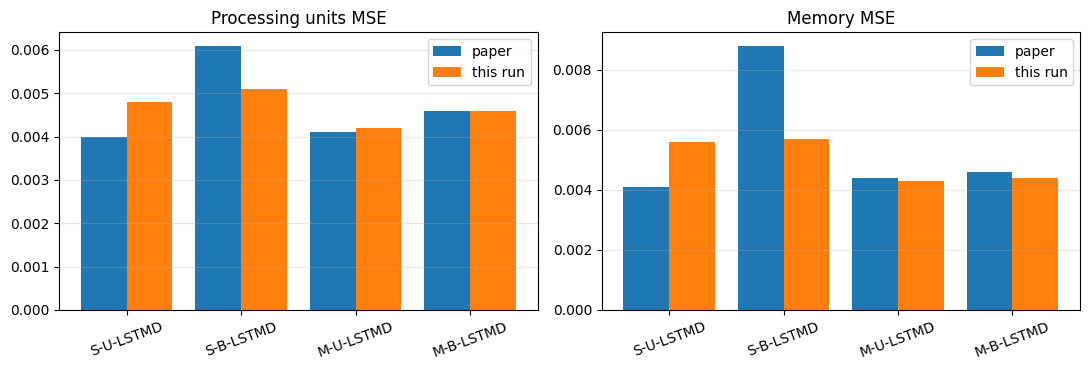


Per-fit log


,model,tag,n_train,epochs_run,best_epoch,best_val_loss,train_minutes,batch_size,optimizer
0,S-U-LSTMD,gc11__cpu,6681,500,412,-1.371489,3.42,256,adam
1,S-U-LSTMD,gc11__mem,6681,500,490,-1.591982,4.08,256,adam
2,S-U-LSTMD,gc19_a__cpu,6681,500,362,-1.362914,4.32,256,adam
3,S-U-LSTMD,gc19_a__mem,6681,500,215,-1.419598,4.02,256,adam
4,S-U-LSTMD,gc19_b__cpu,6681,500,360,-1.209003,4.78,256,rmsprop
5,S-U-LSTMD,gc19_b__mem,6681,500,464,-1.362440,4.03,256,adam
6,S-U-LSTMD,gc19_c__cpu,6681,500,487,-1.261981,3.58,512,adam
7,S-U-LSTMD,gc19_c__mem,6681,500,480,-1.295254,4.92,256,adam
8,S-U-LSTMD,gc19_d__cpu,6681,500,409,-1.295891,3.28,256,adam
9,S-U-LSTMD,gc19_d__mem,6681,500,480,-1.292598,3.58,512,adam


In [6]:
import matplotlib.pyplot as plt
from IPython.display import display

metrics = pd.DataFrame(state["metrics"])
order = [f"{m}-{MODEL_NAME}" for m in ["S-U", "S-B", "M-U", "M-B"] if f"{m}-{MODEL_NAME}" in set(metrics["model"])]
agg = metrics.groupby(["model", "resource"]).agg(MSE=("MSE", "mean"), MAE=("MAE", "mean"), traces=("dataset", "nunique"))

rows, cmp_rows = [], []
for m in order:
    c, r = agg.loc[(m, "avgcpu")], agg.loc[(m, "avgmem")]
    rows.append({"Model": m, "CPU_MSE": c.MSE, "CPU_MAE": c.MAE, "Memory_MSE": r.MSE, "Memory_MAE": r.MAE, "traces": int(c.traces)})
    pm = PAPER[m]
    cmp_rows.append({"Model": m, "CPU_MSE": c.MSE, "paper_CPU_MSE": pm[0], "CPU_MAE": c.MAE, "paper_CPU_MAE": pm[1],
                     "Memory_MSE": r.MSE, "paper_Memory_MSE": pm[2], "Memory_MAE": r.MAE, "paper_Memory_MAE": pm[3], "traces": int(c.traces)})
table1 = pd.DataFrame(rows).round(4)
table1_cmp = pd.DataFrame(cmp_rows).round(4)
table1.to_csv(OUT / f"{MODEL_NAME}_table1.csv", index=False)
table1_cmp.to_csv(OUT / f"{MODEL_NAME}_table1_vs_paper.csv", index=False)

print("Table 1 - average MSE/MAE over the 12 traces (processing units = CPU, memory)")
display(table1)
print("\nSame, next to the paper's values")
display(table1_cmp)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(len(table1_cmp))
for ax, (col, pcol, ttl) in zip(axes, [("CPU_MSE", "paper_CPU_MSE", "Processing units MSE"), ("Memory_MSE", "paper_Memory_MSE", "Memory MSE")]):
    ax.bar(x - 0.2, table1_cmp[pcol], 0.4, label="paper"); ax.bar(x + 0.2, table1_cmp[col], 0.4, label="this run")
    ax.set_xticks(x, table1_cmp["Model"], rotation=20); ax.set_title(ttl); ax.legend(); ax.grid(axis="y", alpha=.3)
fig.tight_layout(); fig.savefig(OUT / f"{MODEL_NAME}_table1_vs_paper.png", dpi=150); plt.show()

print("\nPer-fit log")
display(pd.DataFrame(state["fits"])[["model", "tag", "n_train", "epochs_run", "best_epoch", "best_val_loss", "train_minutes", "batch_size", "optimizer"]])

## 6. Verify saved models and zip everything

Models are saved as `.keras` and their output is `[mean | raw_scale]`. To reuse one elsewhere:

```python
m = keras.models.load_model(path, compile=False)
raw = m.predict(X)                      # X: (N, 288, channels)
d = raw.shape[-1] // 2
mean, std = raw[:, :d], np.logaddexp(0, raw[:, d:])
```

In [7]:
# sanity check: reload one saved model and compare with the stored predictions
fit = state["fits"][-1]
reloaded = keras.models.load_model(OUT / "models" / fit["model_file"], compile=False)
job = next(j for j in jobs_for(fit["model"].split("-LSTMD")[0]) if j["tag"] == fit["tag"])
t0 = job["eval"][0]
Xte = WINDOWS[t0][2][:, :, job["cols"]][:256]
mean, _ = mean_std(reloaded.predict(Xte, verbose=0))
stored = state["preds"][job["mode"]]
stored = stored[(stored.dataset == t0) & (stored.resource == RESOURCES[job["cols"][0]])].sort_values("step")["pred"].to_numpy()[:len(mean)]
print(f"Reloaded {fit['model_file']}: max |reloaded - stored prediction| = {np.abs(mean[:, 0] - stored).max():.2e}")

zip_path = OUT.parent / f"{MODEL_NAME}_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.rglob("*")):
        if f.is_file() and f.parent.name != "ckpt":
            z.write(f, f.relative_to(OUT.parent))
print("\nFiles in", OUT)
for f in sorted(OUT.glob("*.csv")) + sorted(OUT.glob("*.png")):
    print(f"  {f.name:42s} {f.stat().st_size/1e3:9.1f} KB")
print(f"  models/: {len(list((OUT/'models').glob('*.keras')))} .keras files | history/: {len(list((OUT/'history').glob('*.csv')))} | predictions/: {len(list((OUT/'predictions').glob('*.csv')))}")
print("ZIP:", zip_path, f"({zip_path.stat().st_size/1e6:.1f} MB)")

Reloaded M-B-LSTMD__all.keras: max |reloaded - stored prediction| = 1.79e-07

Files in /kaggle/working/lstmd_output
  LSTMD_fit_log.csv                                4.7 KB
  LSTMD_model_metrics.csv                          7.6 KB
  LSTMD_service_level_metrics.csv                129.1 KB
  LSTMD_table1.csv                                 0.2 KB
  LSTMD_table1_vs_paper.csv                        0.4 KB
  LSTMD_table1_vs_paper.png                       53.8 KB
  models/: 39 .keras files | history/: 39 | predictions/: 4
ZIP: /kaggle/working/LSTMD_results.zip (14.7 MB)
